# 5 GSPS MIMO loopback on the ZCU208 (`mimo_mts_5g`)

A tutorial walk through the `MIMO_5G_ZCU208` overlay: load a waveform, play it on all 8 RF-DACs at 5 GSPS, capture
it on all 8 RF-ADCs through loopback cables, and check what came back: one waveform per DAC, latency, channel
alignment, spectrum, phase continuity over the capture, baseband after the mixers, and the CW and loop modes.

**Hardware.** ZCU208 with CLK104, one equal-length cable from each DAC to the ADC of the same number
(DAC *n* → ADC *n*, *n* = 0…7). Copy `mimo_mts_5g.bit` and `.hwh` to `mimo_mts/overlays/zcu208/` on the board.

## How the samples move

| Path | Width and clock | Memory |
|---|---|---|
| DAC | one `wave_gen` per DAC (`transmitter/dac0` … `dac7`): 320-bit rows (20 int16) at 250 MHz → 160 bits at 500 MHz → DAC *n* | 4096 rows per DAC: 81,920 int16 = 40,960 I/Q pairs = 16.4 µs (complex 2.5 GSPS, interpolation 2) |
| ADC | RFDC 160 bits at 500 MHz → 2:1 to 320 bits at 250 MHz → `axi_wave_cap`, one per I and Q stream (16) | 2048 rows: 40,960 samples = 8.2 µs at 5 GSPS |

Software sees each memory as a flat int16 array in sample order; the width conversion between the power-of-two AXI
bus and the 320-bit rows is done by the address mapping (design notes: `doc/wave_gen.md`). `ol.write_dac_complex()`
writes the same waveform to every DAC, `ol.write_dac_iq_buf_ch(n, i, q)` the waveform of DAC *n*. Each generator plays
single (once per trigger), loop or CW (a constant I/Q from registers); all generators share the trigger and an apply
pulse that switches their modes and CW values on the same clock.

In [1]:
%cd /home/xilinx/jupyter_notebooks/pynq_llrf/

/home/xilinx/jupyter_notebooks/pynq_llrf


In [2]:
import asyncio
import time

import matplotlib.pyplot as plt
import numpy as np

from mimo_mts.overlay import MimoMtsOverlay
from mimo_mts.utils.plot import plot_adc_psd, plot_complex_wfm_stack

%load_ext autoreload
%autoreload 2

In [3]:
ol = MimoMtsOverlay(config="MIMO_5G_ZCU208")
ol

< MimoMtsOverlay >:
{ 'bitfile_name': PosixPath('/home/xilinx/jupyter_notebooks/pynq_llrf/mimo_mts/overlays/zcu208/mimo_mts_5g.bit'),
  'board': Board(name='ZCU208',
                 active_adc_tiles=15,
                 active_dac_tiles=15,
                 max_adc_sampling_rate=5000000000.0,
                 max_dac_sampling_rate=7000000000.0,
                 converters_per_tile=2,
                 adc_ref_tile=225,
                 dac_ref_tile=230),
  'clk104_tcs': { 'lmk_tcs': PosixPath('/home/xilinx/jupyter_notebooks/pynq_llrf/mimo_mts/utils/clk104/LMK04828_500M_CLKin0.tcs'),
                  'lmxadc_tcs': PosixPath('/home/xilinx/jupyter_notebooks/pynq_llrf/mimo_mts/utils/clk104/LMX2594_5G.tcs'),
                  'lmxdac_tcs': PosixPath('/home/xilinx/jupyter_notebooks/pynq_llrf/mimo_mts/utils/clk104/LMX2594_5G.tcs')},
  'ioc': {'decimation': 20},
  'rfdc': { 'adc_decimation_factor': 1,
            'dac_interpolation_factor': 2,
            'mixer': { 'adc_mixer_mode': 3,
     

In [4]:
fs = ol.adc_sampling_rate  # 5 GSPS, ADC and DAC
fs_ghz = fs / 1e9
fs_iq = ol.dac_sampling_rate / 2  # complex rate of the DAC input (interpolation 2)
f_dsp = 250e6  # rf_control, wave_gen and capture clock
n_adc = ol.board.n_adcs
print(f"fs = {fs_ghz} GSPS; DAC input {fs_iq / 1e9} GSPS complex")
print(f"generator: {ol.wave_gen.wave_mem.size} int16 = {ol.wave_gen.wave_mem.size / 2 / fs_iq * 1e6:.1f} us")
print(f"ADC capture: {ol.adc_bufs[0].size} samples = {ol.adc_bufs[0].size / fs * 1e6:.1f} us per stream")

fs = 5.0 GSPS; DAC input 2.5 GSPS complex
generator: 81920 int16 = 16.4 us
ADC capture: 40960 samples = 8.2 us per stream


## Trigger and captures

`axil_rf_control` makes the trigger (internal, 10 Hz here). The generator and all 17 captures start on it. The
generator plays the whole memory (`wave_length = 0`), the captures record `pulse_length` rows (clamped to their
2048-row depth).

At high trigger rates a capture can be overwritten while it is being read. Two ways to avoid that:
**one-shot mode** (capture once per `ol.arm_captures()`, then hold until read) and the **capture-done interrupt**
(`ol.write_done_irq`). Both need a bitstream from commit b751729 or later; `capture()` below falls back to waiting a
few trigger periods on older ones.

In [6]:
period_s = 0.1
rc = ol.rf_control.register_map
rc.trig_sel = 0  # internal trigger
rc.trig_period = int(period_s * f_dsp)
rc.trig_delay = 0
rc.trig_divide = 1
rc.dac_enable = 1
rc.pulse_length = 0xFFFF  # capture rows, clamped to 2048
for wg in ol.wave_gens:
    wg.trigger_mode = 1  # play on the rf_control trigger
    wg.wave_length = 0  # play all 4096 rows
    wg.mode = wg.MODE_SINGLE
ol.apply_dac_settings()
print(f"{len(ol.wave_gens)} waveform generators, register map version 0x{ol.wave_gen.version:x}")

8 waveform generators, register map version 0x20000


In [7]:
HAS_CAPTURE_CSR = True


def capture(timeout_s=1.0):
    """Fresh captures on the next trigger: one-shot arm/done if available, else wait a few trigger periods."""
    if not HAS_CAPTURE_CSR:
        time.sleep(3 * period_s + 0.05)
        return True
    ol.capture_oneshot = True
    ol.arm_captures()
    return ol.wait_captures(timeout_s)

In [8]:
async def wait_irqs(n=5):
    irq = ol.write_done_irq
    t0 = time.perf_counter()
    for _ in range(n):
        await irq.wait()
        t1 = time.perf_counter()
        print(f"capture done, {t1 - t0:.4f} s since the last")
        t0 = t1


if hasattr(ol, "write_done_irq"):
    ol.capture_oneshot = False  # capture on every trigger for this test
    asyncio.get_event_loop().run_until_complete(wait_irqs())
else:
    print("no capture interrupt in this bitstream")

capture done, 0.0008 s since the last
capture done, 0.0601 s since the last
capture done, 0.0999 s since the last
capture done, 0.1004 s since the last
capture done, 0.0998 s since the last


## 1. Load a waveform

A 200 MHz complex tone, 2 µs long with raised-cosine edges, followed by zeros. The DAC interpolates by 2 and the
fine mixer is at 0 Hz, so each DAC outputs a real 200 MHz burst. `write_dac_complex` interleaves I and Q into the
generator memory; any write size or order works and no flush is needed.

Text(0.5, 1.0, 'written waveform (I)')

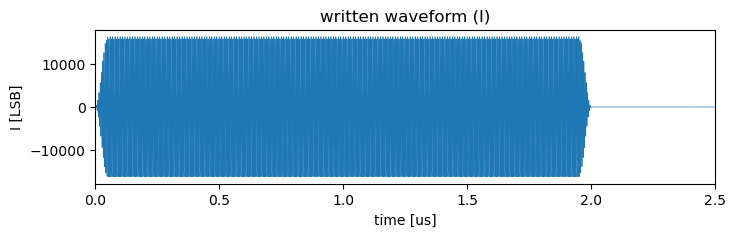

In [9]:
n_iq = ol.wave_gen.wave_mem.size // 2
t_iq = np.arange(n_iq) / fs_iq
f_c = 200e6
pulse_s, edge_s = 2e-6, 50e-9
env = np.clip(np.minimum(t_iq, pulse_s - t_iq) / edge_s, 0, 1)
env = 0.5 - 0.5 * np.cos(np.pi * env)  # raised-cosine edges
amp = 0.5 * (2**15 - 1)
dac_wfm = amp * env * np.exp(2j * np.pi * f_c * t_iq)


def load_burst():
    """Mixers at 0 Hz and the 200 MHz burst in the generator (sections 2-4 call this, so they can run in any order)."""
    ol.set_dac_mixer(freq_mhz=0)
    ol.set_adc_mixer(freq_mhz=0)
    ol.write_dac_complex(dac_wfm)


load_burst()

plt.figure(figsize=(8, 2))
plt.plot(t_iq * 1e6, dac_wfm.real, lw=0.5)
plt.xlim(0, 2.5)
plt.xlabel("time [us]")
plt.ylabel("I [LSB]")
plt.title("written waveform (I)")

## 2. One waveform per DAC

Each DAC has its own generator memory. Here DAC *n* plays the same 2 µs burst delayed by *n* × 0.5 µs, so the
loopback captures show a staircase: the burst on ADC *n* starts *n* × 500 ns after the one on ADC0 (plus the few-ps
cable and channel skews of section 4).

ADC0: burst at   205.4 ns,  +0.0 ns from n x 500 ns
ADC1: burst at   705.4 ns,  +0.0 ns from n x 500 ns
ADC2: burst at  1205.4 ns,  +0.0 ns from n x 500 ns
ADC3: burst at  1705.4 ns,  +0.0 ns from n x 500 ns
ADC4: burst at  2205.4 ns,  +0.0 ns from n x 500 ns
ADC5: burst at  2705.4 ns,  +0.0 ns from n x 500 ns
ADC6: burst at  3205.4 ns,  +0.0 ns from n x 500 ns
ADC7: burst at  3705.4 ns,  +0.0 ns from n x 500 ns


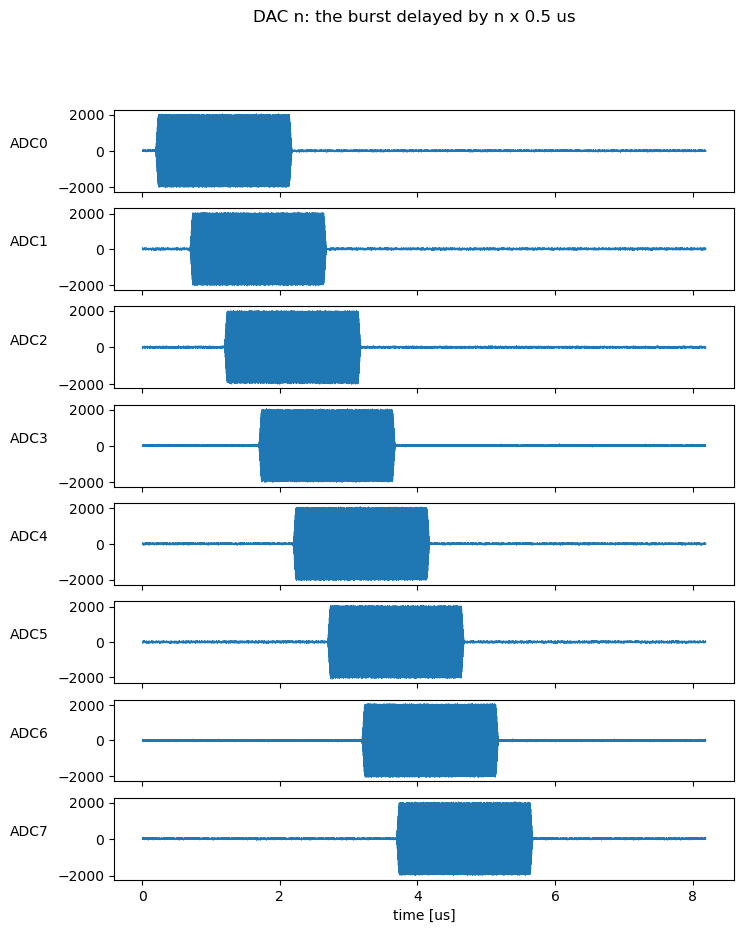

In [10]:
delay_s = 0.5e-6
ol.set_dac_mixer(freq_mhz=0)
ol.set_adc_mixer(freq_mhz=0)
for ch in range(len(ol.wave_gens)):
    t = t_iq - ch * delay_s
    e = np.clip(np.minimum(t, pulse_s - t) / edge_s, 0, 1)
    e = 0.5 - 0.5 * np.cos(np.pi * e)
    w = amp * e * np.exp(2j * np.pi * f_c * t_iq)
    ol.write_dac_iq_buf_ch(ch, w.real, w.imag)
capture()
adc_i, _ = ol.capture_adc_iq_buf()
t_adc = np.arange(adc_i.shape[1]) / fs

fig, axes = plt.subplots(n_adc, 1, sharex=True, figsize=(8, 10))
for ch, ax in enumerate(axes):
    ax.plot(t_adc * 1e6, adc_i[ch], lw=0.4)
    ax.set_ylabel(f"ADC{ch}", rotation=0, labelpad=20)
axes[-1].set_xlabel("time [us]")
fig.suptitle("DAC n: the burst delayed by n x 0.5 us")

onset = [int(np.argmax(np.abs(x) > 0.3 * np.abs(x).max())) for x in adc_i]
for ch, n in enumerate(onset):
    skew_ns = (n - onset[0]) / fs_ghz - ch * delay_s * 1e9
    print(f"ADC{ch}: burst at {n / fs_ghz:7.1f} ns, {skew_ns:+5.1f} ns from n x 500 ns")

## 3. Loopback: all 8 ADCs

With the ADC mixer at 0 Hz, I holds the real 5 GSPS samples (Q is 0). The burst arrives after the loopback latency:
DAC and ADC pipelines plus the cable. With multi-tile sync (MTS) and equal cables the latency is the same on every
channel and on every overlay load.

ADC0: burst starts at sample 1027 = 205.4 ns after the capture start
ADC1: burst starts at sample 1027 = 205.4 ns after the capture start
ADC2: burst starts at sample 1028 = 205.6 ns after the capture start
ADC3: burst starts at sample 1027 = 205.4 ns after the capture start
ADC4: burst starts at sample 1027 = 205.4 ns after the capture start
ADC5: burst starts at sample 1027 = 205.4 ns after the capture start
ADC6: burst starts at sample 1027 = 205.4 ns after the capture start
ADC7: burst starts at sample 1027 = 205.4 ns after the capture start


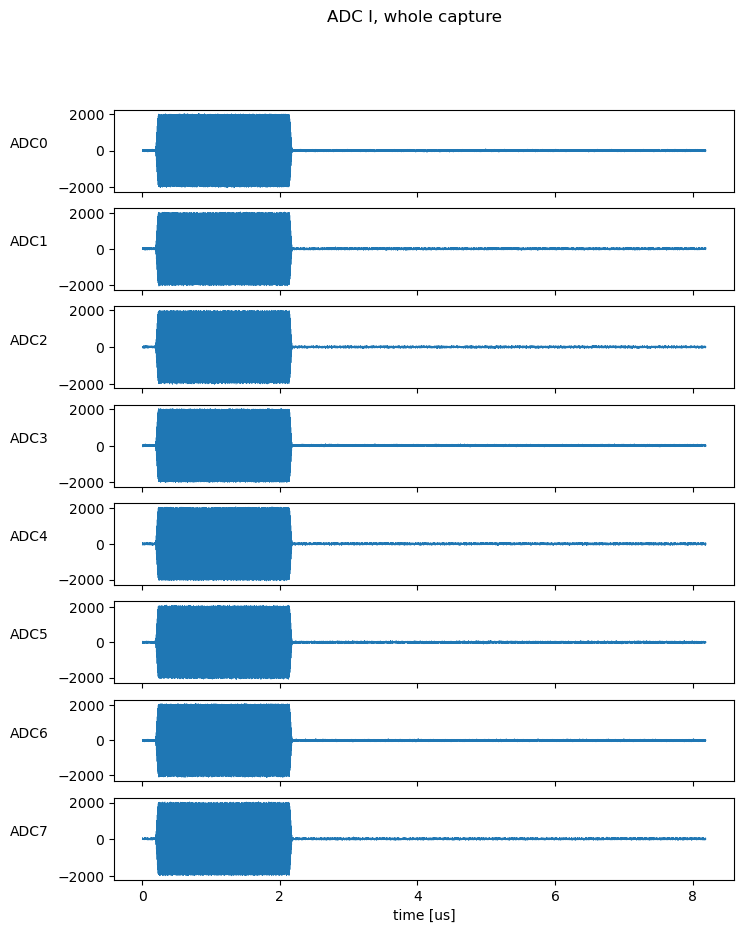

In [11]:
load_burst()
capture()
adc_i, adc_q = ol.capture_adc_iq_buf()
t_adc = np.arange(adc_i.shape[1]) / fs

fig, axes = plt.subplots(n_adc, 1, sharex=True, figsize=(8, 10))
for ch, ax in enumerate(axes):
    ax.plot(t_adc * 1e6, adc_i[ch], lw=0.4)
    ax.set_ylabel(f"ADC{ch}", rotation=0, labelpad=20)
axes[-1].set_xlabel("time [us]")
fig.suptitle("ADC I, whole capture")

onset = [int(np.argmax(np.abs(x) > 0.3 * np.abs(x).max())) for x in adc_i]
for ch, n in enumerate(onset):
    print(f"ADC{ch}: burst starts at sample {n} = {n / fs_ghz:.1f} ns after the capture start")

Text(0.5, 0.98, 'rising edge of the burst')

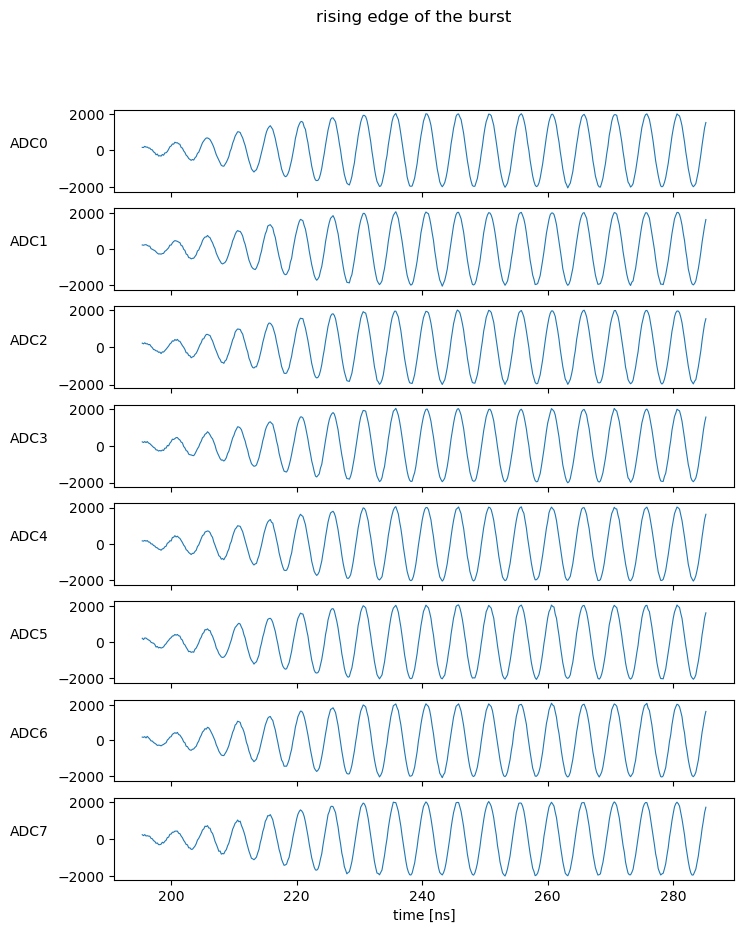

In [12]:
n0 = min(onset)
fig, axes = plt.subplots(n_adc, 1, sharex=True, figsize=(8, 10))
for ch, ax in enumerate(axes):
    ax.plot(t_adc[n0 - 50 : n0 + 400] * 1e9, adc_i[ch, n0 - 50 : n0 + 400], lw=0.8)
    ax.set_ylabel(f"ADC{ch}", rotation=0, labelpad=20)
axes[-1].set_xlabel("time [ns]")
fig.suptitle("rising edge of the burst")

## 4. Channel alignment

Two measures per channel, both against ADC0: the rising edge of the burst (50 % of the envelope, averaged over one
carrier period and interpolated; good to a fraction of a sample, 200 ps) and the phase of the 200 MHz carrier on the
flat top of the burst (picoseconds; the edge resolves its 5 ns ambiguity). With MTS and equal cables both stay at a
fixed value from capture to capture; the carrier delays show the cable and channel skews.

In [13]:
def edge_times(adc_i, smooth=25):
    """Burst rising edge per channel [samples]: 50 % crossing of the envelope, averaged over one carrier period
    (25 samples at 200 MHz) and interpolated between samples. None if the capture holds no burst edge."""
    k = np.ones(smooth) / smooth
    out = []
    for x in adc_i:
        env = np.convolve(np.abs(x.astype(float)), k, mode="same")
        half = 0.5 * np.percentile(env, 99)
        above = np.flatnonzero(env >= half)
        if above.size == 0 or above[0] == 0 or env.max() < 1000:
            out.append(None)
            continue
        n = above[0]
        out.append(n - 1 + (half - env[n - 1]) / (env[n] - env[n - 1]))
    return out


def carrier_delays_ps(adc_i, t_edge, f=f_c, settle=100e-9, length=1e-6):
    """Delay vs ADC0 from the carrier phase on the flat top of the burst [ps]; unambiguous within +-1/(2f) = 2.5 ns,
    which the edge times already resolve."""
    n0 = int(t_edge + settle * fs)
    n = np.arange(n0, n0 + int(length * fs))
    ph = np.array([np.angle(np.sum(x[n] * np.exp(-2j * np.pi * f * n / fs))) for x in adc_i.astype(float)])
    dph = np.angle(np.exp(1j * (ph - ph[0])))
    return -dph / (2 * np.pi * f) * 1e12


load_burst()
for run in range(3):
    capture()
    adc_i, _ = ol.capture_adc_iq_buf()
    t = edge_times(adc_i)
    if t[0] is None:
        print(f"run {run}: no burst edge in this capture")
        continue
    print(f"run {run}: edge at {t[0] / fs_ghz:.1f} ns")
    print("   edge delay vs ADC0 [samples]:   ", [None if x is None else round(x - t[0], 2) for x in t])
    print("   carrier delay vs ADC0 [ps]:     ", np.round(carrier_delays_ps(adc_i, t[0]), 1).tolist())

run 0: edge at 210.7 ns
   edge delay vs ADC0 [samples]:    [0.0, -0.05, -0.13, 0.83, -0.49, -0.13, 0.11, -0.42]
   carrier delay vs ADC0 [ps]:      [-0.0, -24.3, -18.9, -9.6, -42.9, -44.4, -43.1, -110.0]
run 1: edge at 210.7 ns
   edge delay vs ADC0 [samples]:    [0.0, 0.42, -0.13, -0.07, -0.45, -0.37, -0.2, -0.2]
   carrier delay vs ADC0 [ps]:      [-0.0, -23.9, -19.0, -9.2, -42.9, -44.0, -42.4, -109.2]
run 2: edge at 210.8 ns
   edge delay vs ADC0 [samples]:    [0.0, -0.08, 0.59, -0.0, 0.11, -0.32, -0.26, -0.16]
   carrier delay vs ADC0 [ps]:      [-0.0, -23.7, -18.4, -9.1, -42.7, -44.5, -42.7, -109.6]


## 5. A CW tone from the DAC NCO, and its spectrum

Write a constant I/Q value and let the DAC fine mixer (NCO) make the tone: the waveform memory then plays DC and
the tone is continuous over the whole capture. The spectrum shows the tone, its harmonics, and the RF-ADC
interleaving spurs (offset spurs at multiples of Fs/8, gain/time-skew images at k·Fs/8 − f; see
`doc/adc_calibration_findings.md`).

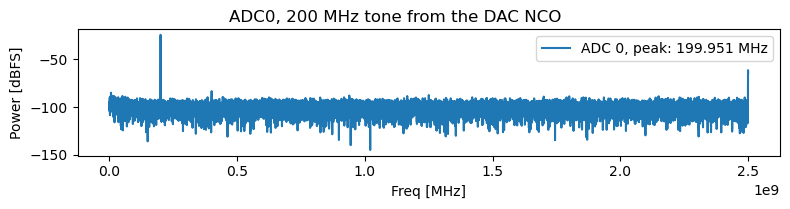

In [14]:
dc = np.full(n_iq, 0.5 * (2**15 - 1), dtype=complex)
ol.write_dac_complex(dc)
ol.set_dac_mixer(freq_mhz=f_c / 1e6)
capture()
adc_i, _ = ol.capture_adc_iq_buf()
plot_adc_psd(adc_i[:1], fs=fs, title="ADC0, 200 MHz tone from the DAC NCO")

## 6. Phase continuity over the 8.2 µs capture

Demodulate each channel at the tone frequency in 40 ns blocks and remove a linear phase fit. A capture without lost
or repeated rows stays flat; one missing 20-sample row (4 ns) would show as a 288° step at 200 MHz. The same check
runs in `mimo_mts/tests/test_mimo5g.py`.

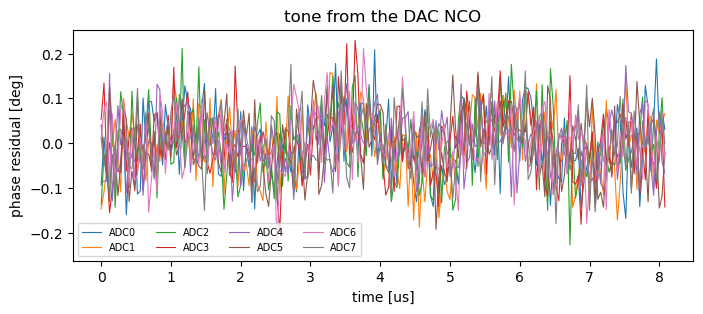

In [15]:
def phase_residual(x, fs, block=200):
    x = x.astype(float)
    spec = np.abs(np.fft.rfft(x * np.hanning(x.size)))
    f0 = np.argmax(spec) * fs / x.size
    z = x * np.exp(-2j * np.pi * f0 * np.arange(x.size) / fs)
    nb = x.size // block
    ph = np.unwrap(np.angle(z[: nb * block].reshape(nb, block).mean(axis=1)))
    k = np.arange(nb)
    return k * block / fs, np.degrees(ph - np.polyval(np.polyfit(k, ph, 1), k))


def plot_continuity(adc_i, title, skip=200):
    """Phase residual from the tone onset (+ skip samples): the generator outputs zeros until it plays."""
    plt.figure(figsize=(8, 3))
    for ch, x in enumerate(adc_i):
        a = np.abs(x.astype(float))
        n0 = int(np.argmax(a > 0.3 * a.max())) + skip
        t, r = phase_residual(x[n0:], fs)
        plt.plot((t + n0 / fs) * 1e6, r, lw=0.8, label=f"ADC{ch}")
    plt.xlabel("time [us]")
    plt.ylabel("phase residual [deg]")
    plt.title(title)
    plt.legend(ncol=4, fontsize=7)


plot_continuity(adc_i, "tone from the DAC NCO")

For comparison, the same tone generated by `wave_gen` (the DAC NCO back at 0 Hz). With the first `mimo_mts_5g`
builds this showed a phase step at a random time, identical on all channels: the generator played forever with
`wave_length = 0` (fixed; `doc/wave_gen.md`, history).

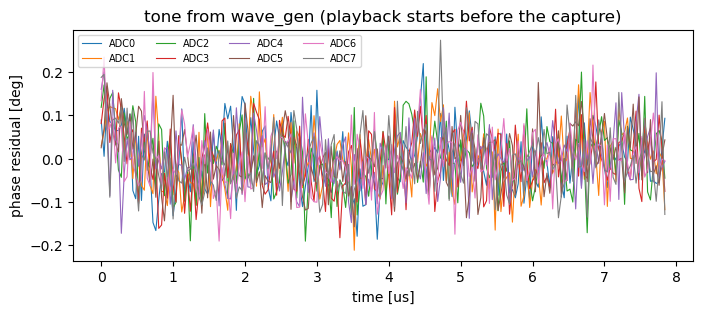

In [16]:
ol.set_dac_mixer(freq_mhz=0)
ol.write_dac_complex(amp * np.exp(2j * np.pi * f_c * t_iq))
capture()
adc_i, _ = ol.capture_adc_iq_buf()
plot_continuity(adc_i[:, 1200:], "tone from wave_gen (playback starts before the capture)")

## 7. Baseband after the mixers

Shift the burst to an intermediate frequency with the DAC NCO and back to baseband with the ADC NCO, then average
20 samples (250 MSPS, the DSP rate). Amplitude and phase should be the same on all channels.

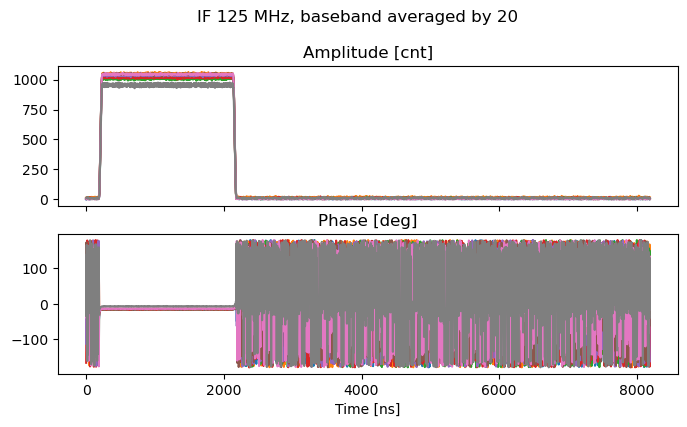

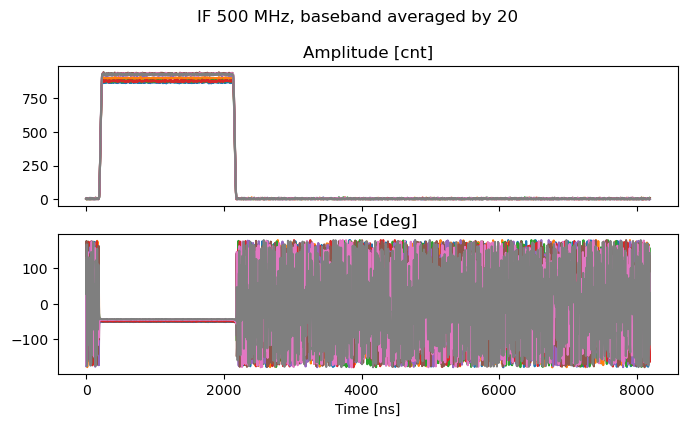

In [17]:
ol.write_dac_complex((amp * env).astype(complex))  # the 2 us burst at baseband
for f_if in (125, 500):
    ol.set_dac_mixer(freq_mhz=f_if)
    ol.set_adc_mixer(freq_mhz=-f_if)
    capture()
    adc_i, adc_q = ol.capture_adc_iq_buf()
    cdata = (adc_i + 1j * adc_q).reshape(n_adc, -1, 20).mean(axis=2)
    plot_complex_wfm_stack(cdata, fs=fs / 20, mode="ap", title=f"IF {f_if} MHz, baseband averaged by 20")

## 8. CW mode: amplitude and phase per DAC

In CW mode a generator streams one I/Q value from its `cw_iq` register instead of its memory, and the DAC NCO makes
the carrier. The mode and the value are staged and take effect on `ol.apply_dac_settings()`, on all DACs on the same
clock (IOC: `DAC{n}:mode`, `DAC{n}:cw:amp`, `DAC{n}:cw:phase`, `DAC:apply`). Here DAC *n* gets phase 45° × *n* and
amplitude 0.5 − 0.05 *n*; the ADC phases relative to the zero-phase setting (which removes the cable and channel
phases) must follow.

active modes: [2, 2, 2, 2, 2, 2, 2, 2] (2 = CW)
DAC0: commanded 0.50 at   0.0 deg -> measured 0.501 at 359.9 deg
DAC1: commanded 0.45 at  45.0 deg -> measured 0.450 at  44.9 deg
DAC2: commanded 0.40 at  90.0 deg -> measured 0.401 at  90.0 deg
DAC3: commanded 0.35 at 135.0 deg -> measured 0.350 at 135.0 deg
DAC4: commanded 0.30 at 180.0 deg -> measured 0.300 at 180.0 deg
DAC5: commanded 0.25 at 225.0 deg -> measured 0.250 at 225.0 deg
DAC6: commanded 0.20 at 270.0 deg -> measured 0.200 at 270.0 deg
DAC7: commanded 0.15 at 315.0 deg -> measured 0.150 at 314.9 deg


Text(0.5, 1.0, 'CW: per-DAC amplitude and phase, relative to the zero-phase setting')

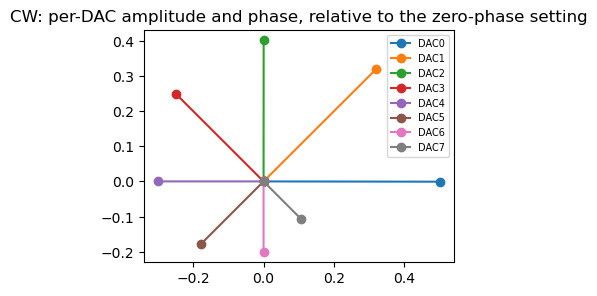

In [21]:
def cw_phasors(amps, phases_deg):
    for wg, a, p in zip(ol.wave_gens, amps, phases_deg, strict=True):
        wg.mode = wg.MODE_CW
        wg.set_cw_amp_phase(a, p)
    ol.apply_dac_settings()
    capture()
    adc_i, _ = ol.capture_adc_iq_buf()
    n = np.arange(2000, adc_i.shape[1])  # skip the first 400 ns
    return np.array([2 * np.mean(x[n] * np.exp(-2j * np.pi * f_c * n / fs)) for x in adc_i.astype(float)])


ol.set_dac_mixer(freq_mhz=f_c / 1e6)
ol.set_adc_mixer(freq_mhz=0)

n_dac = len(ol.wave_gens)
ref = cw_phasors([0.5] * n_dac, [0.0] * n_dac)
amps = [0.5 - 0.05 * ch for ch in range(n_dac)]
phases = [45.0 * ch for ch in range(n_dac)]
z = cw_phasors(amps, phases) / ref
print("active modes:", [wg.active_mode for wg in ol.wave_gens], "(2 = CW)")
for ch in range(n_dac):
    print(
        f"DAC{ch}: commanded {amps[ch]:.2f} at {phases[ch]:5.1f} deg -> measured {0.5 * abs(z[ch]):.3f} at "
        f"{np.degrees(np.angle(z[ch])) % 360:5.1f} deg"
    )

plt.figure(figsize=(4, 4))
for ch in range(n_dac):
    zz = 0.5 * z[ch]
    plt.plot([0, zz.real], [0, zz.imag], "-o", label=f"DAC{ch}")
plt.gca().set_aspect("equal")
plt.legend(fontsize=7)
plt.title("CW: per-DAC amplitude and phase, relative to the zero-phase setting")

## 9. Loop mode

In loop mode a trigger starts playback that repeats rows 0 … `wave_length` − 1 until the mode changes. A 1024-row
waveform (4.096 µs) with a whole number of tone cycles fills the 8.2 µs capture without a phase jump at the wraps;
in single mode the same waveform would stop after 4.1 µs. `wave_length` is latched when playback starts, so set it
before switching to loop mode.

1024 rows = 4.096 us, 199.9512 MHz; busy: [1, 1, 1, 1, 1, 1, 1, 1]


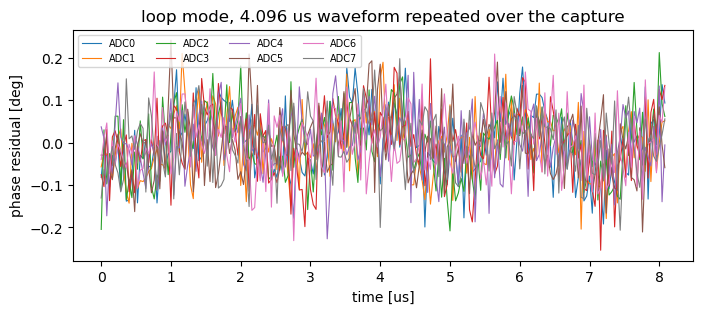

In [24]:
rows = 1024
t_loop = rows * 10 / fs_iq  # 10 I/Q pairs per row
f_loop = round(f_c * t_loop) / t_loop  # whole number of cycles per loop
ol.set_dac_mixer(freq_mhz=0)
ol.set_adc_mixer(freq_mhz=0)

ol.write_dac_complex(amp * np.exp(2j * np.pi * f_loop * t_iq))
for wg in ol.wave_gens:
    wg.wave_length = rows
time.sleep(0.001)  # let a single pass of the old length finish
for wg in ol.wave_gens:
    wg.mode = wg.MODE_LOOP
ol.apply_dac_settings()
time.sleep(2 * period_s)  # the loop starts on the next trigger; capture a later one, mid-loop

capture()
adc_i, _ = ol.capture_adc_iq_buf()
print(f"{rows} rows = {t_loop * 1e6:.3f} us, {f_loop / 1e6:.4f} MHz; busy:", [int(wg.busy) for wg in ol.wave_gens])
plot_continuity(adc_i, f"loop mode, {t_loop * 1e6:.3f} us waveform repeated over the capture")

In [25]:
# restore the defaults
for wg in ol.wave_gens:
    wg.mode = wg.MODE_SINGLE
    wg.wave_length = 0
ol.apply_dac_settings()
ol.set_dac_mixer(freq_mhz=0)
ol.set_adc_mixer(freq_mhz=0)
if HAS_CAPTURE_CSR:
    ol.capture_oneshot = False

## Notes

- The same checks without plots (per-DAC tones, CW phase and amplitude, loop mode, continuity):
  `sudo -E python3 mimo_mts/tests/test_mimo5g.py --repeat 3 --nco`.
- The generator, capture, modes and memory layout: `doc/wave_gen.md`; plans: `doc/development_plan.md`.